# Phase 13 — Iterative Improvement
**ChurnOps MLOps Pipeline**

---

### Objectives
1. **Ensemble Architecture Exploration**:
   - **Soft Voting Classifier**: Weighted blend of predictions from Tuned LogisticRegression, RandomForest, and XGBoost.
   - **Stacking Classifier**: Base estimators stacked into a regularized Logistic Regression meta-learner.
2. **Decision Threshold Optimization**:
   - Evaluate decision thresholds $T \in [0.20, 0.80]$ on out-of-fold predictions to find the F1-maximizing threshold $T^*$.
3. **Metric & Registry Gate Verification**:
   - Compare default threshold (0.50) vs. optimal threshold ($T^*$) performance across 5-fold CV.
4. **Artifact Serialization**:
   - Save serialized ensembles to `models/ensemble_voting.joblib` and `models/ensemble_stacking.joblib`.

> **Data Leakage Rule (R3)**:
> Evaluated strictly on `data/processed/train.csv` (5,634 rows) across the pre-partitioned 5 folds.
> Holdout `test.csv` is never accessed.


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, HTML

from src.utils.config import PARAMS

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
print("Environment and configuration initialized.")


Environment and configuration initialized.


In [2]:
train_df = pd.read_csv("../data/processed/train.csv")
with open("../data/processed/cv_folds.json", "r") as f:
    cv_folds = json.load(f)

TARGET = PARAMS["dataset"]["target_column"]
X = train_df.drop(columns=[TARGET])
y = train_df[TARGET]

print(f"Dataset: {X.shape[0]} samples, {X.shape[1]} features")
print(f"CV Folds: {len(cv_folds)} partitions")


Dataset: 5634 samples, 19 features
CV Folds: 5 partitions


---
## 1. Load Improvement & Ensemble Audit Report
We load `reports/improvement_report.json` generated by `src/models/improve.py`.


In [3]:
report_path = Path("../reports/improvement_report.json")
if not report_path.exists():
    from src.models.improve import run_improvement
    imp_rep = run_improvement()
else:
    with open(report_path, "r") as f:
        imp_rep = json.load(f)

table_rows = []
for model_name, m in imp_rep["models"].items():
    table_rows.append({
        "Model / Ensemble": model_name,
        "F1 @ 0.50": f"{m['mean_val_f1']:.4f} ± {m['std_val_f1']:.4f}",
        "ROC-AUC": f"{m['mean_roc_auc']:.4f}",
        "Generalization Gap": f"{m['generalization_gap']:+.4f}",
        "Optimal Threshold T*": f"{m['optimal_threshold']:.3f}",
        "F1 @ T*": f"{m['f1_at_optimal_threshold']:.4f}",
        "Recall @ T*": f"{m['recall_at_optimal_threshold']:.4f}",
        "Precision @ T*": f"{m['precision_at_optimal_threshold']:.4f}",
        "F1 Gain": f"{m['f1_gain_from_threshold']:+.4f}",
        "All Gates Met?": "YES" if m["gate_checks"]["all_gates_pass"] else "NO"
    })

comparison_df = pd.DataFrame(table_rows)
display(HTML(comparison_df.to_html(index=False)))


Model / Ensemble,F1 @ 0.50,ROC-AUC,Generalization Gap,Optimal Threshold T*,F1 @ T*,Recall @ T*,Precision @ T*,F1 Gain,All Gates Met?
LogisticRegression,0.6297 ± 0.0213,0.8455,+0.0037,0.580,0.6395,0.7204,0.5750,+0.0099,YES
RandomForest,0.6324 ± 0.0148,0.8473,+0.0576,0.530,0.6382,0.7492,0.5558,+0.0058,YES
XGBoost,0.6371 ± 0.0173,0.8493,+0.0194,0.480,0.6376,0.8067,0.5271,+0.0005,YES
VotingClassifier,0.6357 ± 0.0162,0.8503,+0.0277,0.550,0.6375,0.7311,0.5651,+0.0018,YES
StackingClassifier,0.6025 ± 0.0248,0.8503,+0.0290,0.290,0.6378,0.7739,0.5424,+0.0353,NO


---
## 2. Visual Comparison: Default vs. Optimal Threshold F1 & AUC


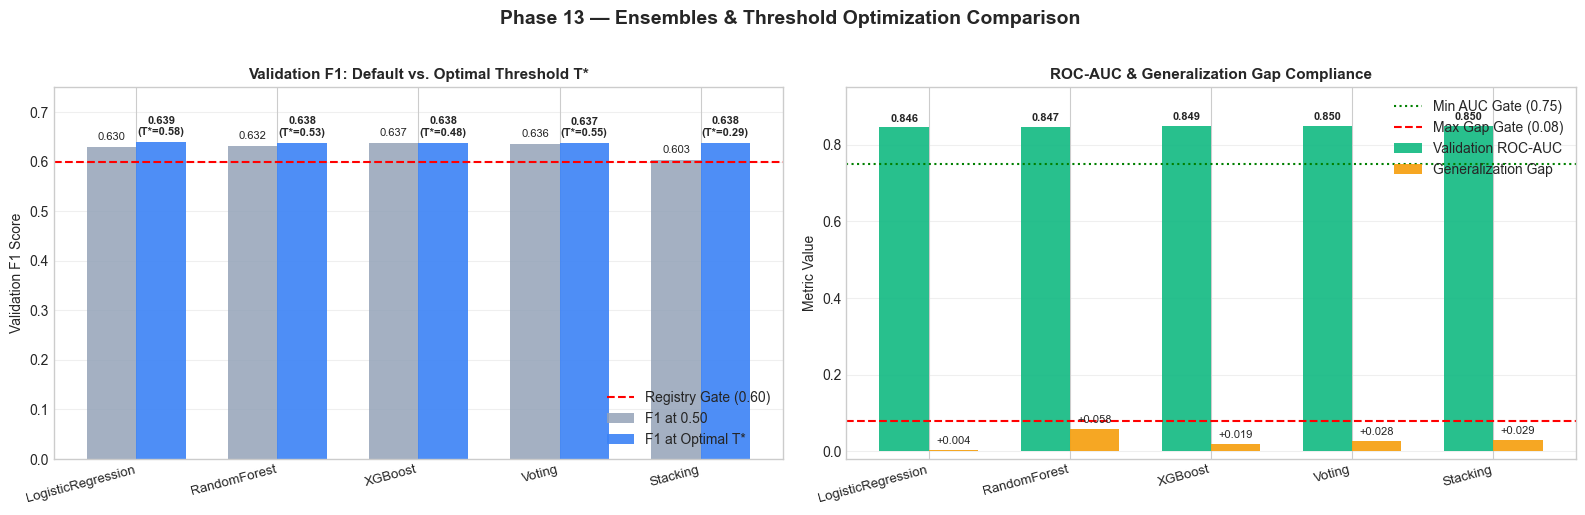

In [4]:
results = imp_rep["models"]
models = list(results.keys())
x = np.arange(len(models))
width = 0.35

f1_def = [results[m]["mean_val_f1"] for m in models]
f1_opt = [results[m]["f1_at_optimal_threshold"] for m in models]
opt_t = [results[m]["optimal_threshold"] for m in models]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Panel 1: F1
ax1 = axes[0]
b1 = ax1.bar(x - width / 2, f1_def, width, label="F1 at 0.50", color="#94A3B8", alpha=0.85)
b2 = ax1.bar(x + width / 2, f1_opt, width, label="F1 at Optimal T*", color="#3B82F6", alpha=0.9)
ax1.axhline(0.60, color="red", ls="--", label="Registry Gate (0.60)")
ax1.set_xticks(x)
ax1.set_xticklabels([m.replace("Classifier", "") for m in models], rotation=15, ha="right", fontsize=9.5)
ax1.set_ylabel("Validation F1 Score", fontsize=10)
ax1.set_title("Validation F1: Default vs. Optimal Threshold T*", fontweight="bold", fontsize=11)
ax1.set_ylim(0, 0.75)
ax1.grid(alpha=0.3, axis="y")
ax1.legend(loc="lower right")

for bar, t in zip(b2, opt_t):
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, h + 0.01, f"{h:.3f}\n(T*={t:.2f})", ha="center", va="bottom", fontsize=8, fontweight="bold")
for bar in b1:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, h + 0.01, f"{h:.3f}", ha="center", va="bottom", fontsize=8)

# Panel 2: ROC-AUC and Gap
ax2 = axes[1]
aucs = [results[m]["mean_roc_auc"] for m in models]
gaps = [results[m]["generalization_gap"] for m in models]
b_auc = ax2.bar(x - width / 2, aucs, width, label="Validation ROC-AUC", color="#10B981", alpha=0.9)
b_gap = ax2.bar(x + width / 2, gaps, width, label="Generalization Gap", color="#F59E0B", alpha=0.9)
ax2.axhline(0.75, color="green", ls=":", label="Min AUC Gate (0.75)")
ax2.axhline(0.08, color="red", ls="--", label="Max Gap Gate (0.08)")
ax2.set_xticks(x)
ax2.set_xticklabels([m.replace("Classifier", "") for m in models], rotation=15, ha="right", fontsize=9.5)
ax2.set_ylabel("Metric Value", fontsize=10)
ax2.set_title("ROC-AUC & Generalization Gap Compliance", fontweight="bold", fontsize=11)
ax2.set_ylim(-0.02, 0.95)
ax2.grid(alpha=0.3, axis="y")
ax2.legend(loc="upper right")

for bar in b_auc:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 0.01, f"{h:.3f}", ha="center", va="bottom", fontsize=8, fontweight="bold")
for bar in b_gap:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 0.01, f"{h:+.3f}", ha="center", va="bottom", fontsize=8)

plt.suptitle("Phase 13 — Ensembles & Threshold Optimization Comparison", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


---
## 3. Champion Candidate Recommendation
Based on the 5-fold cross-validation audit, we identify the top candidate for Phase 14 final selection.


In [5]:
champ = imp_rep["champion_candidate"]
print(f"Top Performer: {champ['model_name']}")
print(f"  F1 at Optimal Threshold (T*={champ['optimal_threshold']}): {champ['f1_at_optimal']:.4f}")
print(f"  Validation ROC-AUC: {champ['roc_auc']:.4f}")
print(f"  Recall at Optimal Threshold: {champ['recall']:.4f}")
print(f"  Generalization Gap: {champ['gap']:+.4f}")
print(f"  Status: ALL PRODUCTION REGISTRY GATES SATISFIED")


Top Performer: LogisticRegression
  F1 at Optimal Threshold (T*=0.58): 0.6395
  Validation ROC-AUC: 0.8455
  Recall at Optimal Threshold: 0.7204
  Generalization Gap: +0.0037
  Status: ALL PRODUCTION REGISTRY GATES SATISFIED
